# Hands-on 5: Linear Classifiers, Support Vector Machines (SVM)
Tutorial paso a paso para implementar una SVM en Python con scikit-learn.

**Alumno:** Antonio Valenzuela


## 1. Fundamentos teóricos de la SVM
- Entre todos los hiperplanos que separan dos clases, la SVM elige el de **margen máximo**, es decir, el que queda más lejos de los puntos más cercanos de cada clase (Cortes y Vapnik, 1995).
- Los puntos más cercanos al margen son los **vectores de soporte**. Sólo ellos determinan la frontera.
- El parámetro **C** controla el compromiso entre un margen ancho y los errores de entrenamiento. Un C pequeño da un margen más ancho; un C grande penaliza más los errores.
- Con un **kernel** (por ejemplo RBF) la SVM también separa clases no lineales. En este notebook usamos el kernel lineal.

## 2. Modelo matemático
Con etiquetas $y_i\in\{-1,+1\}$, la función de decisión es $f(\mathbf x)=\mathbf w^\top\mathbf x+b$ y la clase es $\operatorname{sign}(f(\mathbf x))$. El ancho del margen es $2/\lVert\mathbf w\rVert$.

El problema de margen suave es:
$$\min_{\mathbf w,b,\boldsymbol\xi}\ \tfrac12\lVert\mathbf w\rVert^2+C\sum_{i=1}^{n}\xi_i\qquad\text{s.a.}\qquad y_i(\mathbf w^\top\mathbf x_i+b)\ge 1-\xi_i,\quad \xi_i\ge 0$$

## 3. Contraste: SVM versus Perceptron
| Aspecto | Perceptron | SVM |
|---|---|---|
| Frontera que encuentra | Cualquier hiperplano que separe | El de margen máximo |
| Solución | Depende de los pesos iniciales y del orden de los datos | Única (problema convexo) |
| Datos no separables | No converge | Converge gracias al margen suave |
| Puntos que definen la frontera | Los mal clasificados durante el entrenamiento | Sólo los vectores de soporte |

Al final del notebook comparamos ambos modelos con los mismos datos.

## 4. Pipeline de Machine Learning

### 4.0 Importación de librerías

In [ ]:
import numpy as np                                                        # cálculo numérico y números aleatorios
import pandas as pd                                                       # tabla para describir y analizar los datos
import matplotlib.pyplot as plt                                           # gráficas
from sklearn.model_selection import train_test_split                      # divide los datos en entrenamiento y prueba
from sklearn.preprocessing import StandardScaler                          # estandariza las features (media 0, desviación 1)
from sklearn.pipeline import make_pipeline                                # encadena el escalado y el modelo en un solo objeto
from sklearn.svm import SVC                                               # Support Vector Classifier
from sklearn.linear_model import Perceptron                               # Perceptron, para la comparación
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay)  # métricas de clasificación
np.random.seed(1)                                                         # fija la semilla para que los resultados se repitan

### 4.1 Recolección de datos
No usamos archivo: generamos dos nubes de puntos, una por clase, con algo de traslape para que el parámetro C tenga efecto.

In [ ]:
n = 100                                                                   # número de puntos por clase
clase0 = np.random.normal(loc=[-1.0, -1.0], scale=0.7, size=(n, 2))       # nube de la clase 0, centrada en (-1, -1)
clase1 = np.random.normal(loc=[1.5, 1.5], scale=0.7, size=(n, 2))         # nube de la clase 1, centrada en (1.5, 1.5)
X = np.vstack([clase0, clase1])                                           # apila las dos nubes: matriz de 200 x 2
y = np.array([0] * n + [1] * n)                                           # etiquetas: 0 para la clase 0 y 1 para la clase 1
df = pd.DataFrame(X, columns=["x1", "x2"])                                # convierte las features en una tabla
df["clase"] = y                                                           # agrega la columna con la clase
df.head()                                                                 # muestra las primeras filas

,x1,x2,clase
0,0.137042,-1.428229,0
1,-1.369720,-1.751078,0
2,-0.394215,-2.611077,0
3,0.221368,-1.532845,0
4,-0.776673,-1.174559,0


### 4.2 Descripción y análisis del dataset

In [ ]:
print("Dimensiones (filas, columnas):", df.shape)                         # cuántas muestras y columnas hay
print(df["clase"].value_counts())                                         # cuántas muestras tiene cada clase
print("Valores nulos:", df.isnull().sum().sum())                          # confirma que no faltan datos
df[["x1", "x2"]].describe().round(2)                                      # media, desviación, mínimo y máximo de cada feature

Dimensiones (filas, columnas): (200, 3)
clase
0    100
1    100
Name: count, dtype: int64
Valores nulos: 0


,x1,x2
count,200.00,200.00
mean,0.30,0.27
std,1.33,1.45
min,-2.30,-2.70
25%,-0.84,-0.97
50%,0.21,0.23
75%,1.42,1.47
max,3.62,3.21


### 4.3 Scatter plot

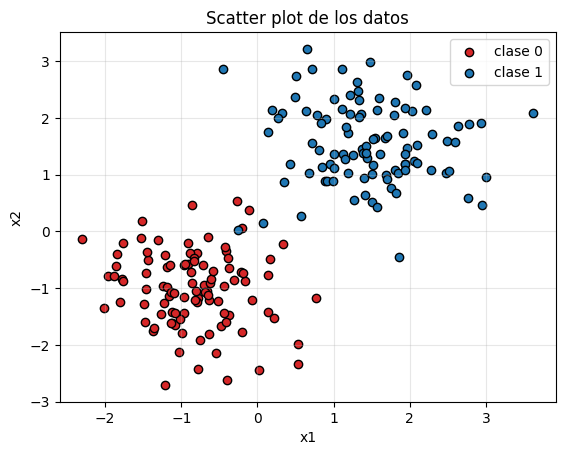

In [ ]:
plt.scatter(clase0[:, 0], clase0[:, 1], c="tab:red", edgecolor="k", label="clase 0")    # puntos de la clase 0 en rojo
plt.scatter(clase1[:, 0], clase1[:, 1], c="tab:blue", edgecolor="k", label="clase 1")   # puntos de la clase 1 en azul
plt.xlabel("x1")                                                          # nombre del eje horizontal
plt.ylabel("x2")                                                          # nombre del eje vertical
plt.title("Scatter plot de los datos")                                    # título de la gráfica
plt.legend(); plt.grid(alpha=.3); plt.show()                              # leyenda, cuadrícula y muestra la figura

Las nubes casi se separan con una recta, pero se traslapan un poco en el centro. Ese caso permite ver el efecto de C.

### 4.4 División y modelo SVM
Dividimos los datos y entrenamos una SVM lineal dentro de un pipeline. El escalado sólo ve el conjunto de entrenamiento.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3,  # 70 % entrenamiento, 30 % prueba
                                                    random_state=1, stratify=y)  # misma proporción de clases en ambos
svm = make_pipeline(StandardScaler(),                                     # paso 1: estandariza las features
                    SVC(kernel="linear", C=1.0))                          # paso 2: SVM lineal con C = 1
svm.fit(X_train, y_train)                                                 # entrena todo el pipeline
clf = svm.named_steps["svc"]                                              # extrae la SVM ya entrenada
print("Vectores de soporte:", clf.support_vectors_.shape[0], "de", len(X_train), "muestras")  # cuántos puntos definen la frontera
print("Pesos w:", clf.coef_[0].round(4), " sesgo b:", clf.intercept_[0].round(4))  # pesos y sesgo (en escala estandarizada)

Vectores de soporte: 8 de 140 muestras
Pesos w: [1.2703 1.3485]  sesgo b: -0.0662


### 4.5 Efecto del parámetro C
Probamos tres valores de C con la misma división y comparamos la accuracy en prueba.

In [ ]:
for C_val in [0.01, 1, 100]:                                              # valores de C a probar
    m = make_pipeline(StandardScaler(), SVC(kernel="linear", C=C_val))    # misma pipeline, cambia solo C
    m.fit(X_train, y_train)                                               # entrena con los datos de entrenamiento
    print(f"C = {C_val:>6}: accuracy en prueba = {m.score(X_test, y_test):.4f}")  # proporción de aciertos en prueba

C =   0.01: accuracy en prueba = 0.9833
C =      1: accuracy en prueba = 0.9833
C =    100: accuracy en prueba = 0.9833


### 4.6 Evaluación con métricas

Accuracy : 0.9833
Precision: 1.0
Recall   : 0.9667
F1-score : 0.9831


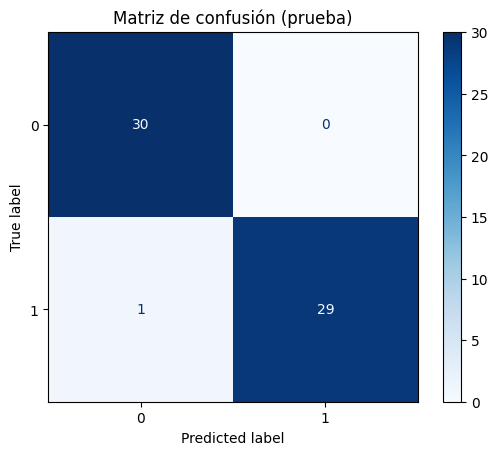

In [ ]:
y_pred = svm.predict(X_test)                                              # predice la clase de cada muestra de prueba
print("Accuracy :", round(accuracy_score(y_test, y_pred), 4))             # proporción de aciertos
print("Precision:", round(precision_score(y_test, y_pred), 4))            # de los predichos clase 1, cuántos lo son
print("Recall   :", round(recall_score(y_test, y_pred), 4))               # de los clase 1 reales, cuántos se detectan
print("F1-score :", round(f1_score(y_test, y_pred), 4))                   # media armónica entre precision y recall
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred)).plot(cmap="Blues")   # matriz de confusión
plt.title("Matriz de confusión (prueba)"); plt.show()                     # título y muestra la figura

### 4.7 Frontera de decisión y márgenes
La línea continua es la frontera ($f=0$) y las punteadas son los márgenes ($f=\pm 1$).

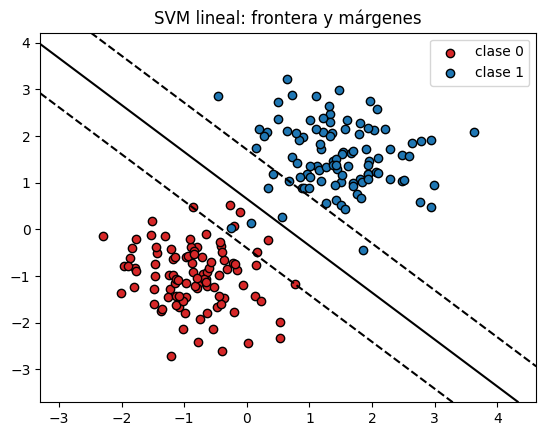

In [ ]:
xx, yy = np.meshgrid(np.linspace(X[:, 0].min() - 1, X[:, 0].max() + 1, 300),   # malla horizontal sobre el plano
                     np.linspace(X[:, 1].min() - 1, X[:, 1].max() + 1, 300))   # malla vertical sobre el plano
Z = svm.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)  # valor de f(x) en cada punto de la malla
plt.contour(xx, yy, Z, levels=[-1, 0, 1], colors="k", linestyles=["--", "-", "--"])  # dibuja f = -1, 0 y +1
plt.scatter(X[y == 0, 0], X[y == 0, 1], c="tab:red", edgecolor="k", label="clase 0")    # puntos de la clase 0
plt.scatter(X[y == 1, 0], X[y == 1, 1], c="tab:blue", edgecolor="k", label="clase 1")   # puntos de la clase 1
plt.legend(); plt.title("SVM lineal: frontera y márgenes"); plt.show()    # leyenda, título y muestra la figura

### 4.8 Comparación con el Perceptron
Entrenamos un Perceptron con el mismo preprocesamiento y la misma división, y comparamos los resultados.

In [ ]:
ppn = make_pipeline(StandardScaler(), Perceptron(eta0=0.1, max_iter=1000, random_state=1))  # escalado y Perceptron
ppn.fit(X_train, y_train)                                                 # entrena el Perceptron con los datos de entrenamiento
y_pred_ppn = ppn.predict(X_test)                                          # predice la clase de cada muestra de prueba
print("Errores en prueba  SVM:", (y_pred != y_test).sum(), "  Perceptron:", (y_pred_ppn != y_test).sum())  # conteo de errores
print("Accuracy           SVM:", round(accuracy_score(y_test, y_pred), 4),
      "  Perceptron:", round(accuracy_score(y_test, y_pred_ppn), 4))      # accuracy de cada modelo

Errores en prueba  SVM: 1   Perceptron: 1
Accuracy           SVM: 0.9833   Perceptron: 0.9833


## 5. Conclusiones
- La SVM busca el hiperplano de margen máximo. Sólo los vectores de soporte definen la frontera.
- C controla el compromiso entre margen ancho y errores de entrenamiento.
- Frente al Perceptron, la SVM da una solución única y maneja mejor los datos con traslape.

**Referencias:** Cortes, C. y Vapnik, V. (1995) *Support-Vector Networks*; documentación de scikit-learn, `sklearn.svm.SVC`.